In [172]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)

In [173]:
from slmsuite.hardware.slms.meadowlark import Meadowlark
from slmsuite.hardware.cameras.alliedvision import AlliedVision
from slmsuite.hardware.cameraslms import FourierSLM

# Paths

SDK_PATH = Path(
    r"C:\Program Files\Meadowlark Optics\Blink 1920 HDMI\SDK"
)

LUT_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Experiment scripts"
    r"\LUT_locked_759nm_20260811_201109\759nm_KS_global_20260811.lut"
)

WAVEFRONT_PHASE_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts"
    r"\YDFC_wavefront_phase_processed_R2p80_50ms_dark.npy"
)



# Initialize hardware ONCE in this notebook


slm = Meadowlark(
    slm_number=1,
    sdk_path=str(SDK_PATH),
    lut_path=str(LUT_PATH),
    wav_um=0.7593,
    verbose=True,
)

# cam = AlliedVision(
#     serial="015C2",
#     verbose=True,
# )

# fs = FourierSLM(cam, slm)

cal_file = r"c:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts\YDFC_fourier_pre_wavefront_00000.h5"

# loaded = fs.load_calibration(
#     "fourier",
#     file_path=cal_file
# )

# print("Loaded:", loaded)
# print("Current calibrations:", fs.calibrations.keys())

# print("Current calibrations:")
# print(fs.calibrations.keys())


# ------------------------------------------------------------
# Load the measured correction from disk
#
# This only creates a NumPy array called wavefront_phase.
# It does NOT activate the correction.
# ------------------------------------------------------------

wavefront_phase = np.load(WAVEFRONT_PHASE_PATH)


# Activate measured wavefront correction in slmsuite
slm.source["phase"] = wavefront_phase.copy()

print("SLM source keys:", slm.source.keys())
print("Wavefront correction enabled:", slm.phase_correct)
print("Correction shape:", slm.source["phase"].shape)

# ------------------------------------------------------------
# Inspect our starting state
# ------------------------------------------------------------

print("SLM shape:", slm.shape)
# print("Camera shape:", cam.shape)

print("\nLoaded correction:")
print(" shape :", wavefront_phase.shape)
print(" finite:", np.all(np.isfinite(wavefront_phase)))
print(" min   :", wavefront_phase.min())
print(" max   :", wavefront_phase.max())

print("\nCurrent slm.source keys:")
print(slm.source.keys())

print("\nGlobal default slm.phase_correct:")
print(slm.phase_correct)

Validating DPI awareness...success
Constructing Blink SDK...success
Loading LUT file...SLM source keys: dict_keys(['phase'])
Wavefront correction enabled: True
Correction shape: (1200, 1920)
SLM shape: (1200, 1920)

Loaded correction:
 shape : (1200, 1920)
 finite: True
 min   : 0.0
 max   : 6.2831762207757835

Current slm.source keys:
dict_keys(['phase'])

Global default slm.phase_correct:
True


In [174]:
# ============================================================
# THREE-REGION ALIGNMENT MASK
# ============================================================

import numpy as np

ny, nx = slm.shape
pixel_mm = 0.008       # 8 um


# ============================================================
# PARAMETERS — ONLY CHANGE THESE
# ============================================================

# Gaussian beam centre from your amplitude measurement
# Use the SAME coordinate convention as your Gaussian-fit plot
X0_MM = -1.00 # real from analysis
Y0_MM =  0.0


# ------------------------------------------------------------
# Region 1: small circular alignment patch
# ------------------------------------------------------------

PATCH_DIAMETER_MM = 9.6

CARRIER_PERIOD_PX = 16       # useful alignment blaze
CARRIER_DIRECTION = "x"


# ------------------------------------------------------------
# Outer useful mask
#
# This defines the maximum SLM area that we eventually want
# to use for holograms.
# ------------------------------------------------------------

MASK_DIAMETER_MM = 12


# ------------------------------------------------------------
# Region 2:
# inside useful mask but outside alignment patch
# ------------------------------------------------------------

DUMP1_PERIOD_PX = 3
DUMP1_DIRECTION = "x"


# ------------------------------------------------------------
# Region 3:
# outside useful mask
# ------------------------------------------------------------

DUMP2_PERIOD_PX = 4
DUMP2_DIRECTION = "x"


# ============================================================
# SLM COORDINATES
# ============================================================

cx = (nx - 1) / 2
cy = (ny - 1) / 2

yy, xx = np.indices((ny, nx))

x_px = xx - cx
y_px = yy - cy

x_mm = x_px * pixel_mm
y_mm = y_px * pixel_mm


# Coordinates relative to measured Gaussian centre
X = x_mm - X0_MM
Y = y_mm - Y0_MM

R = np.sqrt(X**2 + Y**2)


# ============================================================
# THREE REGIONS
# ============================================================

patch_radius_mm = PATCH_DIAMETER_MM / 2
mask_radius_mm  = MASK_DIAMETER_MM / 2


# Region 1:
# central circular alignment patch
region1 = R <= patch_radius_mm


# Region 2:
# useful hologram area outside alignment patch
region2 = (
    (R > patch_radius_mm)
    & (R <= mask_radius_mm)
)


# Region 3:
# everything outside useful mask
region3 = R > mask_radius_mm


# ============================================================
# BLAZE FUNCTION
# ============================================================

def make_blaze(period_px, direction):

    if direction == "x":
        coordinate = x_px

    elif direction == "y":
        coordinate = y_px

    else:
        raise ValueError("direction must be 'x' or 'y'")

    return 2 * np.pi * coordinate / period_px


# ============================================================
# MAKE THREE PHASE PATTERNS
# ============================================================

phase_carrier = make_blaze(
    CARRIER_PERIOD_PX,
    CARRIER_DIRECTION
)

phase_dump1 = make_blaze(
    DUMP1_PERIOD_PX,
    DUMP1_DIRECTION
)

phase_dump2 = make_blaze(
    DUMP2_PERIOD_PX,
    DUMP2_DIRECTION
)


# ============================================================
# COMBINE
# ============================================================

phase_alignment = np.zeros((ny, nx))

phase_alignment[region1] = phase_carrier[region1]
phase_alignment[region2] = phase_dump1[region2]
phase_alignment[region3] = phase_dump2[region3]

phase_alignment = np.mod(
    phase_alignment,
    2*np.pi
)


print("=== Alignment mask ===")
print("SLM shape              :", phase_alignment.shape)
print("Beam/mask centre [mm]  :", X0_MM, Y0_MM)
print("Patch diameter [mm]    :", PATCH_DIAMETER_MM)
print("Outer mask diameter [mm]:", MASK_DIAMETER_MM)

print()
print("Region 1:", CARRIER_PERIOD_PX, "px", CARRIER_DIRECTION, "blaze")
print("Region 2:", DUMP1_PERIOD_PX, "px", DUMP1_DIRECTION, "dump")
print("Region 3:", DUMP2_PERIOD_PX, "px", DUMP2_DIRECTION, "dump")

=== Alignment mask ===
SLM shape              : (1200, 1920)
Beam/mask centre [mm]  : -1.0 0.0
Patch diameter [mm]    : 9.6
Outer mask diameter [mm]: 12

Region 1: 16 px x blaze
Region 2: 3 px x dump
Region 3: 4 px x dump


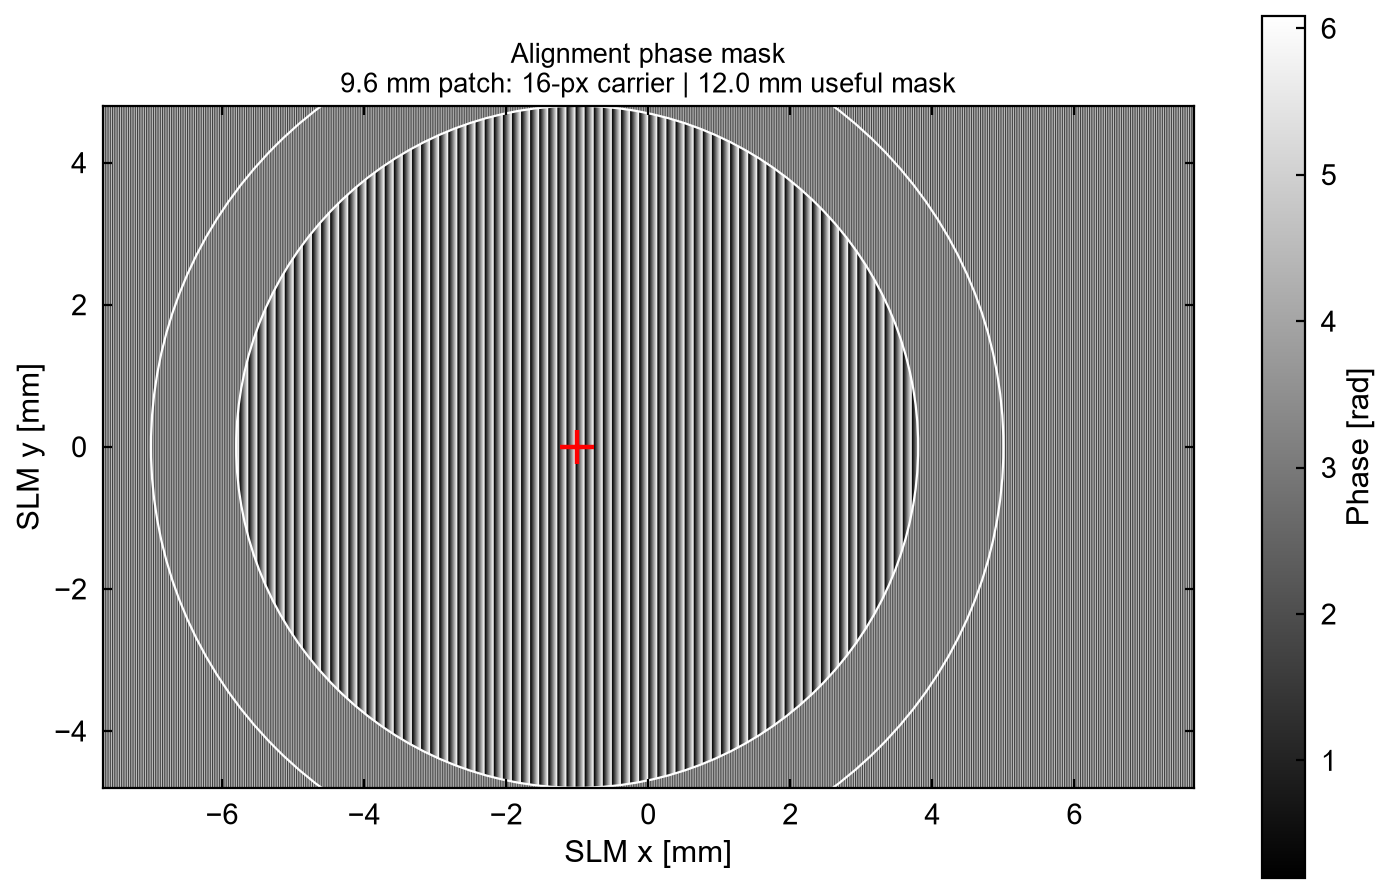

In [175]:
# ============================================================
# PLOT PHASE PATTERN
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

im = plt.imshow(
    phase_alignment,
    origin="lower",
    cmap="gray",
    extent=[
        x_mm.min(),
        x_mm.max(),
        y_mm.min(),
        y_mm.max()
    ]
)

plt.colorbar(im, label="Phase [rad]")


# Inner alignment-patch boundary
inner_circle = plt.Circle(
    (X0_MM, Y0_MM),
    patch_radius_mm,
    fill=False,
    color="white",
    linewidth=1
)

plt.gca().add_patch(inner_circle)


# Outer useful-mask boundary
outer_circle = plt.Circle(
    (X0_MM, Y0_MM),
    mask_radius_mm,
    fill=False,
    color="white",
    linewidth=1
)

plt.gca().add_patch(outer_circle)


# Measured Gaussian centre
plt.plot(
    X0_MM,
    Y0_MM,
    "r+",
    markersize=15,
    markeredgewidth=2
)


plt.xlabel("SLM x [mm]")
plt.ylabel("SLM y [mm]")

plt.title(
    "Alignment phase mask\n"
    f"{PATCH_DIAMETER_MM:.1f} mm patch: "
    f"{CARRIER_PERIOD_PX}-px carrier | "
    f"{MASK_DIAMETER_MM:.1f} mm useful mask"
)

plt.xlim(-7.68, 7.68)
plt.ylim(-4.8, 4.8)

plt.show()

In [176]:
print("Writing three-region alignment mask to SLM...")

slm.set_phase(
    phase_alignment,
    phase_correct=True,
    settle=True,
)

print("Done.")

Writing three-region alignment mask to SLM...
Done.


## annular for seeing back reflected fringes


In [195]:
# ============================================================
# ANNULAR (DONUT) ALIGNMENT MASK
# ============================================================

import numpy as np

ny, nx = slm.shape
pixel_mm = 0.008       # 8 um


# ============================================================
# PARAMETERS — ONLY CHANGE THESE
# ============================================================

# Gaussian beam centre from your amplitude measurement
X0_MM = -1.00
Y0_MM =  0.00


# ------------------------------------------------------------
# Region 1: ANNULAR alignment beam
# ------------------------------------------------------------

# Central hole of donut on SLM
#
# With 3.333x relay:
# 2.2 mm on SLM -> 7.33 mm at objective
#
# Physical objective hole = 6 mm,
# so this gives some safety margin.
INNER_DIAMETER_MM = 1.8


# Outer diameter of annulus on SLM
#
# 9.6 mm on SLM -> 32 mm at objective
OUTER_DIAMETER_MM = 9.6


# Carrier applied ONLY to the annulus
CARRIER_PERIOD_PX = 16
CARRIER_DIRECTION = "x"


# ------------------------------------------------------------
# Maximum useful SLM area
# ------------------------------------------------------------

MASK_DIAMETER_MM = 12


# ------------------------------------------------------------
# Dump grating for everything inside useful mask
# but NOT belonging to the annulus
# ------------------------------------------------------------

DUMP1_PERIOD_PX = 3
DUMP1_DIRECTION = "x"


# ------------------------------------------------------------
# Dump grating outside useful mask
# ------------------------------------------------------------

DUMP2_PERIOD_PX = 4
DUMP2_DIRECTION = "x"


# ============================================================
# SLM COORDINATES
# ============================================================

cx = (nx - 1) / 2
cy = (ny - 1) / 2

yy, xx = np.indices((ny, nx))

x_px = xx - cx
y_px = yy - cy

x_mm = x_px * pixel_mm
y_mm = y_px * pixel_mm


# Coordinates relative to measured Gaussian centre
X = x_mm - X0_MM
Y = y_mm - Y0_MM

R = np.sqrt(X**2 + Y**2)


# ============================================================
# RADII
# ============================================================

inner_radius_mm = INNER_DIAMETER_MM / 2
outer_radius_mm = OUTER_DIAMETER_MM / 2
mask_radius_mm  = MASK_DIAMETER_MM / 2


# ============================================================
# THREE PHASE REGIONS
# ============================================================

# Region 1:
# ANNULUS -> useful alignment beam
region1 = (
    (R >= inner_radius_mm)
    & (R <= outer_radius_mm)
)


# Region 2:
# Everything inside the useful mask that is NOT the annulus
#
# This includes:
#   1. central hole
#   2. area between outer annulus edge and MASK_DIAMETER_MM
#
region2 = (
    (R <= mask_radius_mm)
    & (~region1)
)


# Region 3:
# Everything outside useful mask
region3 = R > mask_radius_mm


# ============================================================
# BLAZE FUNCTION
# ============================================================

def make_blaze(period_px, direction):

    if direction == "x":
        coordinate = x_px

    elif direction == "y":
        coordinate = y_px

    else:
        raise ValueError("direction must be 'x' or 'y'")

    return 2 * np.pi * coordinate / period_px


# ============================================================
# MAKE PHASE PATTERNS
# ============================================================

phase_carrier = make_blaze(
    CARRIER_PERIOD_PX,
    CARRIER_DIRECTION
)

phase_dump1 = make_blaze(
    DUMP1_PERIOD_PX,
    DUMP1_DIRECTION
)

phase_dump2 = make_blaze(
    DUMP2_PERIOD_PX,
    DUMP2_DIRECTION
)


# ============================================================
# COMBINE
# ============================================================

phase_alignment = np.zeros((ny, nx))

phase_alignment[region1] = phase_carrier[region1]
phase_alignment[region2] = phase_dump1[region2]
phase_alignment[region3] = phase_dump2[region3]

phase_alignment = np.mod(
    phase_alignment,
    2*np.pi
)


# ============================================================
# PRINT INFO
# ============================================================

relay_mag = 1000 / 300

print("=== ANNULAR Alignment Mask ===")
print("SLM shape                 :", phase_alignment.shape)
print("Beam/mask centre [mm]     :", X0_MM, Y0_MM)

print()
print("Inner diameter SLM [mm]   :", INNER_DIAMETER_MM)
print("Outer diameter SLM [mm]   :", OUTER_DIAMETER_MM)

print()
print("Expected at objective:")
print(
    "Inner diameter [mm]       :",
    INNER_DIAMETER_MM * relay_mag
)
print(
    "Outer diameter [mm]       :",
    OUTER_DIAMETER_MM * relay_mag
)

print()
print("Region 1: annulus ->",
      CARRIER_PERIOD_PX, "px",
      CARRIER_DIRECTION, "carrier")

print("Region 2: non-annulus inside mask ->",
      DUMP1_PERIOD_PX, "px",
      DUMP1_DIRECTION, "dump")

print("Region 3: outside mask ->",
      DUMP2_PERIOD_PX, "px",
      DUMP2_DIRECTION, "dump")

=== ANNULAR Alignment Mask ===
SLM shape                 : (1200, 1920)
Beam/mask centre [mm]     : -1.0 0.0

Inner diameter SLM [mm]   : 1.8
Outer diameter SLM [mm]   : 9.6

Expected at objective:
Inner diameter [mm]       : 6.0
Outer diameter [mm]       : 32.0

Region 1: annulus -> 16 px x carrier
Region 2: non-annulus inside mask -> 3 px x dump
Region 3: outside mask -> 4 px x dump


In [196]:
print("Writing annular alignment mask to SLM...")

slm.set_phase(
    phase_alignment,
    phase_correct=True,
    settle=True,
)

print("Done.")

Writing annular alignment mask to SLM...
Done.


## 3x3

In [194]:
## 3x3

# ============================================================
# SIMPLE 3x3 TWEEZER ARRAY
# 5 um spacing in atom plane
#
# No GS
# No WGS
# No feedback
# Equal target amplitudes
# ============================================================

import numpy as np


# ============================================================
# PARAMETERS
# ============================================================

LAMBDA = 759.3e-9          # m
F_OBJ  = 26.9e-3           # m

# SLM -> objective pupil magnification
RELAY_MAG = 1000 / 300     # = 3.333...

PIXEL_SIZE = 8e-6          # SLM pixel pitch [m]

SPACING = 5e-6             # tweezer spacing in atom plane [m]


# ============================================================
# SLM COORDINATES
# ============================================================

ny, nx = slm.shape

cx = (nx - 1) / 2
cy = (ny - 1) / 2

yy, xx = np.indices((ny, nx))

x_slm = (xx - cx) * PIXEL_SIZE
y_slm = (yy - cy) * PIXEL_SIZE


# ============================================================
# 3x3 TARGET POSITIONS
#
# positions:
#
# (-5,+5)   (0,+5)   (+5,+5)
# (-5, 0)   (0, 0)   (+5, 0)
# (-5,-5)   (0,-5)   (+5,-5)
#
# units: um in atom plane
# ============================================================

positions = []

for iy in [-1, 0, 1]:
    for ix in [-1, 0, 1]:

        x_target = ix * SPACING
        y_target = iy * SPACING

        positions.append((x_target, y_target))


# ============================================================
# COHERENT SUM OF 9 PLANE WAVES
# ============================================================

field = np.zeros((ny, nx), dtype=np.complex128)

for x_target, y_target in positions:

    # Required SLM spatial phase gradients.
    #
    # Relay magnification must be included because a spatial
    # period on the SLM becomes RELAY_MAG times larger at the
    # objective pupil.

    kx = (
        2 * np.pi
        * RELAY_MAG
        * x_target
        / (LAMBDA * F_OBJ)
    )

    ky = (
        2 * np.pi
        * RELAY_MAG
        * y_target
        / (LAMBDA * F_OBJ)
    )

    phase = kx * x_slm + ky * y_slm

    field += np.exp(1j * phase)


# ============================================================
# PHASE-ONLY HOLOGRAM
# ============================================================

phase_3x3 = np.angle(field)

# convert [-pi, pi] -> [0, 2pi)
phase_3x3 = np.mod(
    phase_3x3,
    2*np.pi
)


# ============================================================
# DIAGNOSTICS
# ============================================================

period_5um = (
    LAMBDA
    * F_OBJ
    / (RELAY_MAG * SPACING)
)

period_5um_px = period_5um / PIXEL_SIZE

print("=== Simple 3x3 hologram ===")
print("Array spacing at atoms :", SPACING * 1e6, "um")
print("Relay magnification    :", RELAY_MAG)
print("Objective focal length :", F_OBJ * 1e3, "mm")
print()
print("Equivalent SLM period for 5 um displacement:")
print("  %.4f mm" % (period_5um * 1e3))
print("  %.2f pixels" % period_5um_px)

print("Writing 3x3 tweezer hologram to SLM...")

slm.set_phase(
    phase_3x3,
    phase_correct=True,
    settle=True,
)

print("Done.")

=== Simple 3x3 hologram ===
Array spacing at atoms : 5.0 um
Relay magnification    : 3.3333333333333335
Objective focal length : 26.9 mm

Equivalent SLM period for 5 um displacement:
  1.2255 mm
  153.19 pixels
Writing 3x3 tweezer hologram to SLM...
Done.


### full SLM 16 pixel blaze

In [18]:
# ============================================================
# FULL-SLM +16 PIXEL BLAZE
# ============================================================

import numpy as np

ny, nx = slm.shape

# SLM coordinates
cy = (ny - 1) / 2
cx = (nx - 1) / 2

yy, xx = np.indices((ny, nx))

x_px = xx - cx
y_px = yy - cy


# ============================================================
# PARAMETERS
# ============================================================

CARRIER_PERIOD_PX = 16     # keep +16: your chosen optical axis
CARRIER_DIRECTION = "x"


# ============================================================
# MAKE FULL-SLM BLAZE
# ============================================================

if CARRIER_DIRECTION == "x":
    coordinate = x_px

elif CARRIER_DIRECTION == "y":
    coordinate = y_px

else:
    raise ValueError("CARRIER_DIRECTION must be 'x' or 'y'")


phase_alignment = (
    2 * np.pi * coordinate / CARRIER_PERIOD_PX
)

phase_alignment = np.mod(
    phase_alignment,
    2*np.pi
)


print("=== Full-SLM alignment blaze ===")
print("SLM shape       :", phase_alignment.shape)
print("Carrier period  :", CARRIER_PERIOD_PX, "px")
print("Carrier direction:", CARRIER_DIRECTION)

=== Full-SLM alignment blaze ===
SLM shape       : (1200, 1920)
Carrier period  : 16 px
Carrier direction: x


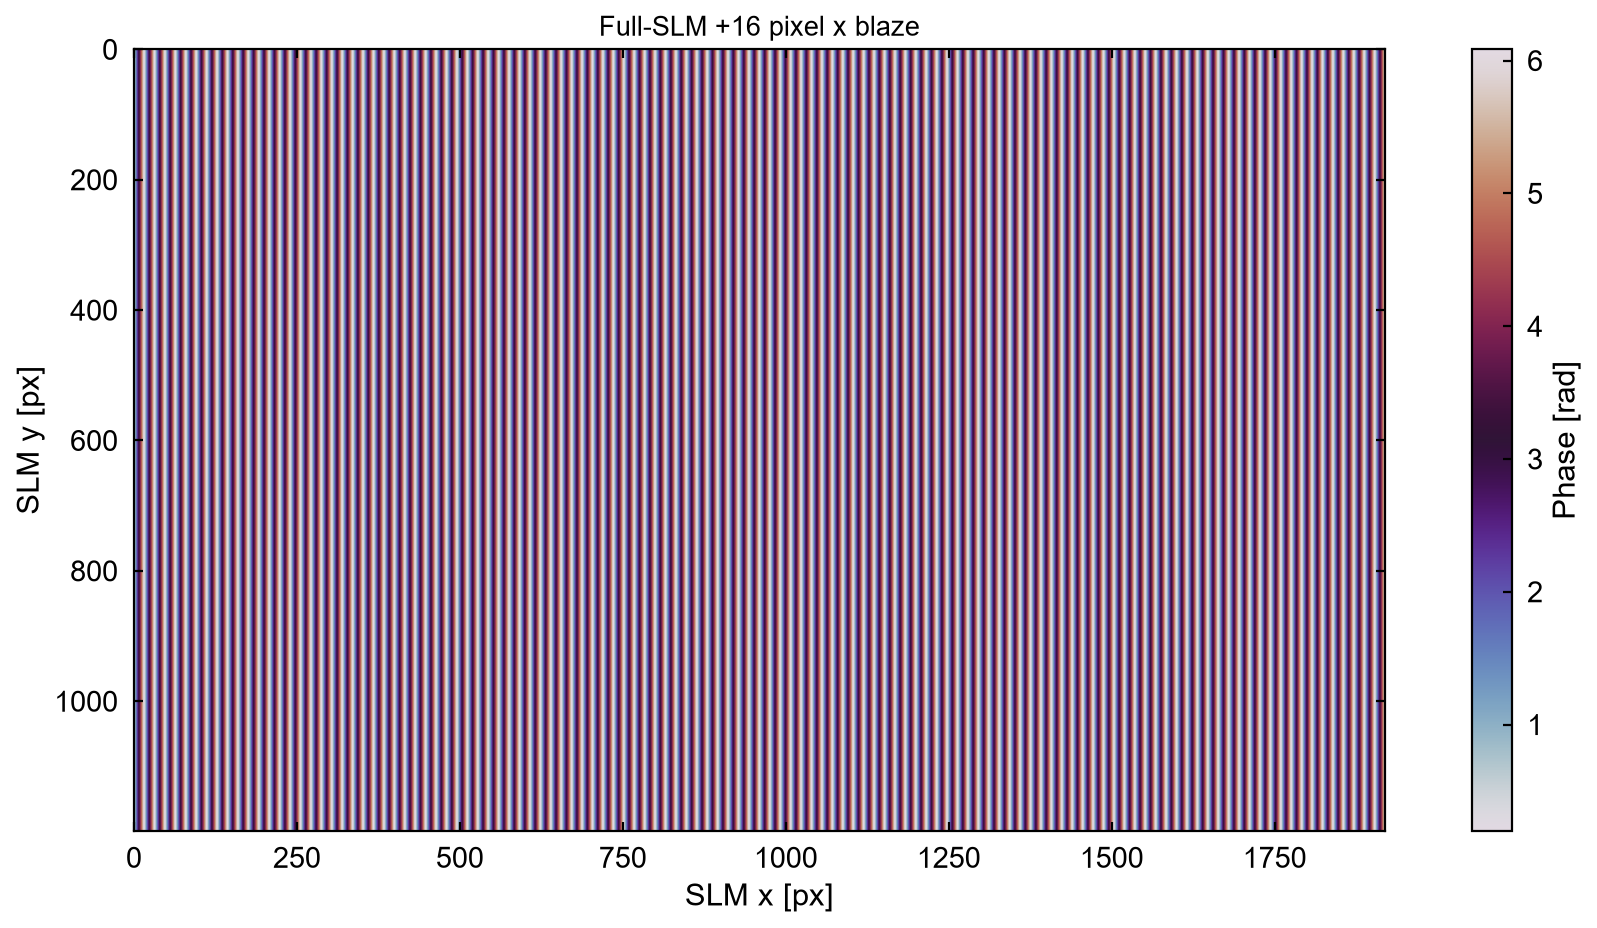

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.imshow(
    phase_alignment,
    cmap="twilight",
    origin="upper"
)

plt.colorbar(label="Phase [rad]")

plt.title("Full-SLM +16 pixel x blaze")
plt.xlabel("SLM x [px]")
plt.ylabel("SLM y [px]")

plt.tight_layout()
plt.show()

In [ ]:
slm.set_phase(
    phase_alignment,
    phase_correct=True,
    settle=True,
)

array([[233, 217, 201, ...,  54,  38,  22],
       [233, 217, 201, ...,  54,  38,  22],
       [233, 217, 201, ...,  54,  38,  22],
       ...,
       [ 90,  74,  58, ..., 167, 151, 135],
       [ 90,  74,  58, ..., 167, 151, 135],
       [ 90,  74,  58, ..., 167, 151, 135]],
      shape=(1200, 1920), dtype=uint8)